# **Text Vectoritation and Feature Extractioon**

In [ ]:

# Cell 1: Loading my dataset

import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

#  Select the uploaded CSV file automatically
csv_file = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head(3))


Saving research_abstracts_6000_cleaned.csv to research_abstracts_6000_cleaned.csv
Dataset loaded successfully!
Shape: (6000, 11)

Column names:
['title', 'abstract', 'label', 'source_url', 'year', 'openalex_id', 'primary_topic', 'subfield', 'field', 'domain', 'topic_score']


,title,abstract,label,source_url,year,openalex_id,primary_topic,subfield,field,domain,topic_score
0,Radiation Resistant Camera System for Monitori...,Radiation resistant camera system was construc...,Science,https://doi.org/10.1585/pfr.15.2402039,2020,https://openalex.org/W3038568908,Magnetic confinement fusion research,Nuclear and High Energy Physics,Physics and Astronomy,Physical Sciences,0.5615
1,Generalized Gradient Approximation Made Simple,Generalized gradient approximations (GGA's) fo...,Science,https://doi.org/10.1103/physrevlett.77.3865,1996,https://openalex.org/W1981368803,Advanced Chemical Physics Studies,"Atomic and Molecular Physics, and Optics",Physics and Astronomy,Physical Sciences,0.9990
2,Efficient iterative schemes for ab initio tota...,We present an efficient scheme for calculating...,Science,https://doi.org/10.1103/physrevb.54.11169,1996,https://openalex.org/W2083222334,Advanced Chemical Physics Studies,"Atomic and Molecular Physics, and Optics",Physics and Astronomy,Physical Sciences,0.9941


In [ ]:

# Cell 2: Validating and cleaning the dataset

required_columns = ["abstract", "label"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

# Removing records without an abstract or label
df = df.dropna(subset=["abstract", "label"]).copy()

# Normalizing whitespace in the abstracts
df["abstract"] = (
    df["abstract"]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Standardizing label formatting
df["label"] = df["label"].astype(str).str.strip()

# Removing empty abstracts
df = df[df["abstract"].str.len() > 0].copy()

# Keeping only the three required classes
valid_labels = [
    "Science",
    "Business",
    "Social Science"
]

df = df[df["label"].isin(valid_labels)].copy()

# Removing exact duplicate abstracts
df = df.drop_duplicates(
    subset=["abstract"],
    keep="first"
).reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts().reindex(valid_labels, fill_value=0))

print("\nMissing values:")
print(df[["abstract", "label"]].isnull().sum())


Rows after cleaning: 6000

Class distribution:
label
Science           2000
Business          2000
Social Science    2000
Name: count, dtype: int64

Missing values:
abstract    0
label       0
dtype: int64


In [ ]:

# Cell 3: Examining abstract lengths

df["word_count"] = df["abstract"].str.split().str.len()

print("Word count statistics:")
print(df["word_count"].describe())

print("\nShortest abstracts:")
display(
    df.nsmallest(5, "word_count")[
        ["label", "word_count", "abstract"]
    ]
)

print("\nLongest abstracts:")
display(
    df.nlargest(5, "word_count")[
        ["label", "word_count", "abstract"]
    ]
)


Word count statistics:
count    6000.000000
mean      155.370667
std       149.831381
min        30.000000
25%        94.000000
50%       132.000000
75%       184.000000
max      5132.000000
Name: word_count, dtype: float64

Shortest abstracts:


,label,word_count,abstract
162,Science,30,S ummary The technique of disc electrophoresis...
711,Science,30,Historical Survey The Modern Approach The Riem...
1156,Science,30,1. Introduction. 2. Simple Regression. 3. Mult...
1277,Science,30,This Letter presents variational ground-state ...
2013,Business,30,ABSTRACT This article surveys research on corp...



Longest abstracts:


,label,word_count,abstract
4230,Social Science,5132,"I propose to consider the question, ‘Can machi..."
2254,Business,3685,Numerous markets are characterized by informat...
5760,Social Science,3569,Over the last few years there has been increas...
5204,Social Science,3072,The notion that self-identity and morality are...
663,Science,2676,The tapestry of life on Earth is unraveling as...


In [ ]:

# Cell 4: Spliting the data

from sklearn.model_selection import train_test_split

X = df["abstract"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training samples: 4800
Testing samples: 1200

Training class distribution:
label
Social Science    1600
Science           1600
Business          1600
Name: count, dtype: int64

Testing class distribution:
label
Business          400
Social Science    400
Science           400
Name: count, dtype: int64


In [ ]:

# Cell 5: TF-IDF feature extraction

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True
)

# Learning vocabulary and IDF weights from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transforming test data using the same learned vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))


Training feature matrix: (4800, 50000)
Testing feature matrix: (1200, 50000)
Vocabulary size: 50000


In [ ]:

# Cell 6: Saving prepared data and TF-IDF features

from scipy.sparse import save_npz
import joblib

# Saving the splits for reproducibility
pd.DataFrame({
    "abstract": X_train,
    "label": y_train
}).to_csv("train_data.csv", index=False)

pd.DataFrame({
    "abstract": X_test,
    "label": y_test
}).to_csv("test_data.csv", index=False)

# Saving numerical TF-IDF matrices
save_npz("X_train_tfidf.npz", X_train_tfidf)
save_npz("X_test_tfidf.npz", X_test_tfidf)

# Saving labels separately
np.save("y_train.npy", y_train.to_numpy())
np.save("y_test.npy", y_test.to_numpy())

# Saving the fitted vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.joblib")

print("All preprocessing outputs saved.")


All preprocessing outputs saved.


In [ ]:
# For downloading these created files
# from google.colab import files

# for filename in [
#     "train_data.csv",
#     "test_data.csv",
#     "X_train_tfidf.npz",
#     "X_test_tfidf.npz",
#     "y_train.npy",
#     "y_test.npy",
#     "tfidf_vectorizer.joblib"
# ]:
#     files.download(filename)


In [ ]:

# Cell 7: Finalizing verification

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_tfidf.shape[1])

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

assert X_train_tfidf.shape[0] == len(y_train)
assert X_test_tfidf.shape[0] == len(y_test)
assert X_train_tfidf.shape[1] == X_test_tfidf.shape[1]

print("\nPreprocessing completed successfully!")


Training samples: 4800
Testing samples: 1200
Number of TF-IDF features: 50000

Training labels:
label
Social Science    1600
Science           1600
Business          1600
Name: count, dtype: int64

Testing labels:
label
Business          400
Social Science    400
Science           400
Name: count, dtype: int64

Preprocessing completed successfully!


**Text Vectoritation and feature extraction using TF-IDF is complete and we move to Model training and Testing**

# **Model Training and Testing**

In [ ]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("TF-IDF features:", X_train_tfidf.shape[1])

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 4800
Testing samples: 1200
TF-IDF features: 50000

Training label distribution:
label
Social Science    1600
Science           1600
Business          1600
Name: count, dtype: int64

Testing label distribution:
label
Business          400
Social Science    400
Science           400
Name: count, dtype: int64


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "kNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        random_state=42,
        max_iter=5000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train_tfidf, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")

print("\nAll six models have been trained.")


Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Naive Bayes...
Naive Bayes trained successfully!

Training kNN...
kNN trained successfully!

Training SVM...
SVM trained successfully!

Training Random Forest...
Random Forest trained successfully!

All six models have been trained.


In [ ]:
import joblib
import os

os.makedirs("trained_models", exist_ok=True)

for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        model,
        f"trained_models/{filename}"
    )

joblib.dump(tfidf, "trained_models/tfidf_vectorizer.joblib")

print("All models and the TF-IDF vectorizer have been saved.")

All models and the TF-IDF vectorizer have been saved.


# **Model Accuracy, F1Score, etc and model Comparison**

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []

for name, model in trained_models.items():
    # Predicting the classes of the test abstracts
    y_pred = model.predict(X_test_tfidf)

    # Calculating evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

# Sort models by F1-score, highest first
results_df = results_df.sort_values(
    by="F1-Score (Macro)", ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Macro)": "{:.4f}",
        "Recall (Macro)": "{:.4f}",
        "F1-Score (Macro)": "{:.4f}"
    })
)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,SVM,0.9108,0.9106,0.9108,0.9104
1,Logistic Regression,0.9008,0.9007,0.9008,0.9007
2,kNN,0.8858,0.8865,0.8858,0.8847
3,Naive Bayes,0.8817,0.8827,0.8817,0.8811
4,Random Forest,0.8575,0.8575,0.8575,0.8555
5,Decision Tree,0.7008,0.7021,0.7008,0.7013


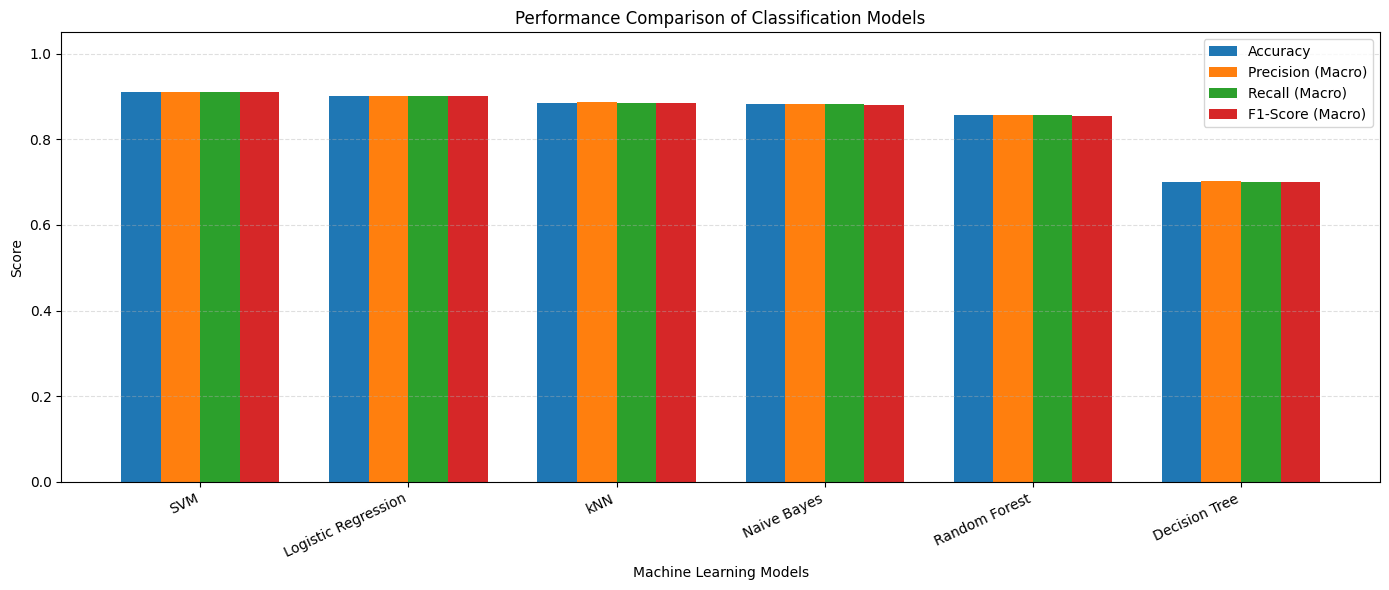

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)"
]

x = np.arange(len(results_df))
width = 0.19

plt.figure(figsize=(14, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        results_df[metric],
        width,
        label=metric
    )

plt.xticks(x, results_df["Model"], rotation=25, ha="right")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.title("Performance Comparison of Classification Models")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


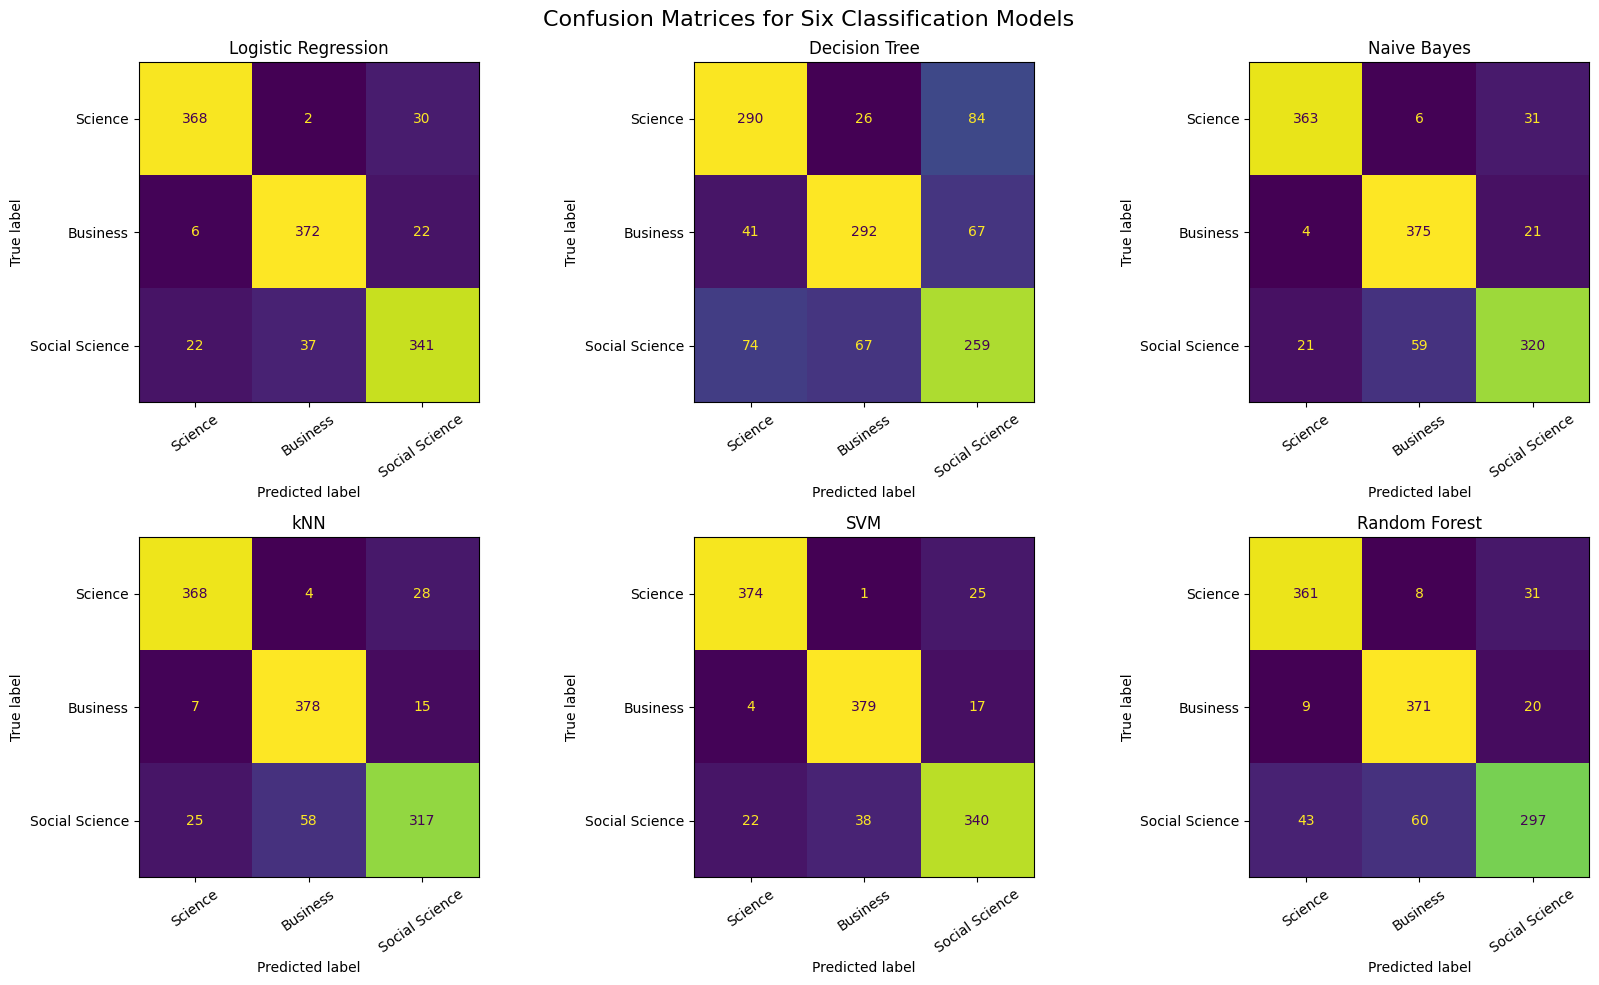

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_labels = ["Science", "Business", "Social Science"]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display_cm.plot(
        ax=axes[i],
        values_format="d",
        colorbar=False
    )

    axes[i].set_title(name)
    axes[i].tick_params(axis="x", labelrotation=35)

plt.suptitle("Confusion Matrices for Six Classification Models", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import classification_report

for name, model in trained_models.items():
    y_pred = model.predict(X_test_tfidf)

    print("\n" + "=" * 65)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 65)

    print(classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_labels,
        zero_division=0,
        digits=4
    ))



CLASSIFICATION REPORT: Logistic Regression
                precision    recall  f1-score   support

       Science     0.9293    0.9200    0.9246       400
      Business     0.9051    0.9300    0.9174       400
Social Science     0.8677    0.8525    0.8600       400

      accuracy                         0.9008      1200
     macro avg     0.9007    0.9008    0.9007      1200
  weighted avg     0.9007    0.9008    0.9007      1200


CLASSIFICATION REPORT: Decision Tree
                precision    recall  f1-score   support

       Science     0.7160    0.7250    0.7205       400
      Business     0.7584    0.7300    0.7439       400
Social Science     0.6317    0.6475    0.6395       400

      accuracy                         0.7008      1200
     macro avg     0.7021    0.7008    0.7013      1200
  weighted avg     0.7021    0.7008    0.7013      1200


CLASSIFICATION REPORT: Naive Bayes
                precision    recall  f1-score   support

       Science     0.9356    0.9075

In [ ]:

results_df.to_csv("model_performance_comparison.csv", index=False)

print("Evaluation results saved successfully.")

# Download the comparison table to your computer
from google.colab import files
files.download("model_performance_comparison.csv")


Evaluation results saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Creating a Demo to classify a random csv**

In [ ]:
# Saving the model and new text vectors


import joblib
import os

os.makedirs("final_model", exist_ok=True)

# Saving the original SVM classifier
joblib.dump(
    trained_models["SVM"],
    "final_model/svm_classifier.joblib"
)

# Saving the fitted TF-IDF vectorizer
joblib.dump(
    tfidf,
    "final_model/tfidf_vectorizer.joblib"
)

print("Final SVM classifier saved.")
print("TF-IDF vectorizer saved.")


Final SVM classifier saved.
TF-IDF vectorizer saved.


In [ ]:
# installing gardio

!pip -q install gradio


In [ ]:
#Demo interface

import gradio as gr
import pandas as pd
import joblib
import tempfile

# Loading the saved classifier and TF-IDF vectorizer
svm_model = joblib.load("final_model/svm_classifier.joblib")
tfidf_vectorizer = joblib.load(
    "final_model/tfidf_vectorizer.joblib"
)


def classify_abstracts(file_path, column_name):
    if file_path is None:
        raise gr.Error("Please upload a CSV file.")

    try:
        data = pd.read_csv(file_path)
    except Exception as e:
        raise gr.Error(f"Unable to read the CSV: {e}")

    column_name = column_name.strip()

    if column_name not in data.columns:
        raise gr.Error(
            f"Column '{column_name}' not found. "
            f"Available columns: {', '.join(data.columns.astype(str))}"
        )

    # Preserving original data and adding predicted labels
    result = data.copy()
    abstracts = result[column_name].fillna("").astype(str).str.strip()

    valid_rows = abstracts.ne("")
    result["predicted_label"] = "No abstract provided"

    if valid_rows.any():
        features = tfidf_vectorizer.transform(
            abstracts[valid_rows]
        )
        predictions = svm_model.predict(features)
        result.loc[valid_rows, "predicted_label"] = predictions

    # Saving predictions as a downloadable CSV
    with tempfile.NamedTemporaryFile(
        suffix=".csv", delete=False
    ) as output:
        output_path = output.name

    result.to_csv(output_path, index=False)

    return result, output_path


demo = gr.Interface(
    fn=classify_abstracts,
    inputs=[
        gr.File(
            label="Upload research abstracts CSV",
            file_types=[".csv"],
            type="filepath"
        ),
        gr.Textbox(
            label="Name of the abstract column",
            value="abstract"
        )
    ],
    outputs=[
        gr.Dataframe(label="Predicted Labels"),
        gr.File(label="Download Results CSV")
    ],
    title="Research Abstract Classification",
    description=(
        "Upload a CSV file containing research abstracts. "
        "The trained SVM model predicts Science, Business, "
        "or Social Science for each non-empty abstract."
    ),
    flagging_mode="never"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d74f1161f9871c54a3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
#Sample CSV for testing

import pandas as pd

sample = pd.DataFrame({
    "title": [
        "Machine Learning for Disease Detection",
        "Consumer Buying Behaviour",
        "Social Inequality in Education"
    ],
    "abstract": [
        "This study develops a machine learning model "
        "for disease detection using clinical data.",
        "This research examines consumer preferences, "
        "marketing strategies, and purchase decisions.",
        "This paper investigates educational inequality, "
        "social mobility, and social class."
    ]
})

sample.to_csv("sample_abstracts.csv", index=False)

print("Sample CSV created successfully.")
display(sample)


Sample CSV created successfully.


,title,abstract
0,Machine Learning for Disease Detection,This study develops a machine learning model f...
1,Consumer Buying Behaviour,"This research examines consumer preferences, m..."
2,Social Inequality in Education,This paper investigates educational inequality...
